# Customer Churn Prediction with Python

This notebook uses the Telco Customer Churn dataset and demonstrates:
- Feature/target separation
- Train/test split
- Preprocessing categorical and numerical features
- Logistic Regression
- Pipeline
- Evaluation with accuracy, precision, recall and F1-score
- Confusion matrix and ROC-AUC
- Prediction for a brand-new customer
- Probability-based churn prediction
- Threshold tuning

> **Dataset note:** The original IBM repository still contains the dataset, but the old filename `WA_Fn-UseC_-Telco-Customer-Churn.csv` is not the path used by IBM's current archived repository. The code below uses IBM's actual file path: `Telco-Customer-Churn.csv`.


## 1. Import libraries

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

print("Libraries imported successfully.")


Libraries imported successfully.


2.Load the Dataset

Load the Telco Customer Churn Dataset in Google Colab


In this project, I’ll load the IBM Telco Customer Churn dataset directly from its GitHub repository.
If the dataset URL is unavailable, I can upload the CSV file manually as an alternative.

Note: The IBM repository uses the filename Telco-Customer-Churn.csv.

In [27]:
import os

print("Current directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current directory: /drive/notebooks
Files in current directory: ['Customer_Churn_Prediction.ipynb', 'Customer_Churn_Prediction_Portfolio_Ready.ipynb', 'Untitled.ipynb', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb', 'Intro.ipynb']


In [28]:

import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Inspect the data

In [29]:

# Check the columns in our dataset
print("Column names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Count customers who churned and stayed
print("\nChurn counts:")
print(df["Churn"].value_counts())

# Calculate churn percentages
print("\nChurn percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values:
customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
dtype: int64

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64


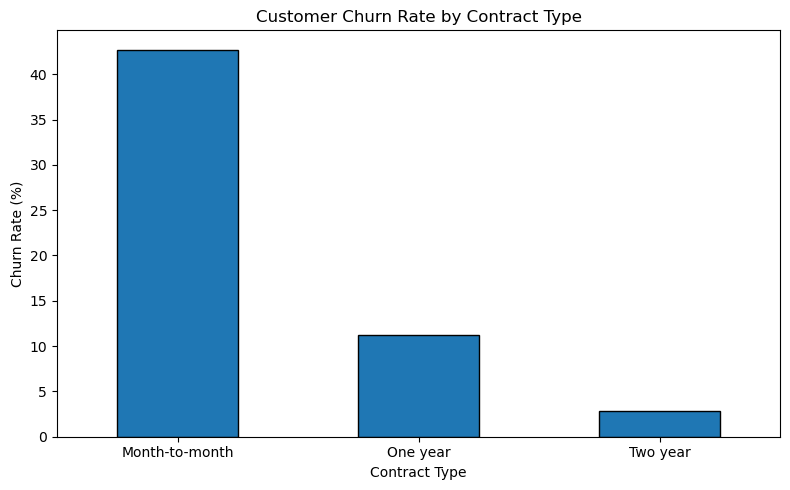

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate churn rate for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

# Select the churn percentage
churn_rate = contract_churn["Yes"].sort_values(
    ascending=False
)

# Display the values
print("Churn rate by contract type:")
print(churn_rate.round(2))

# Create the chart
plt.figure(figsize=(8, 5))

churn_rate.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


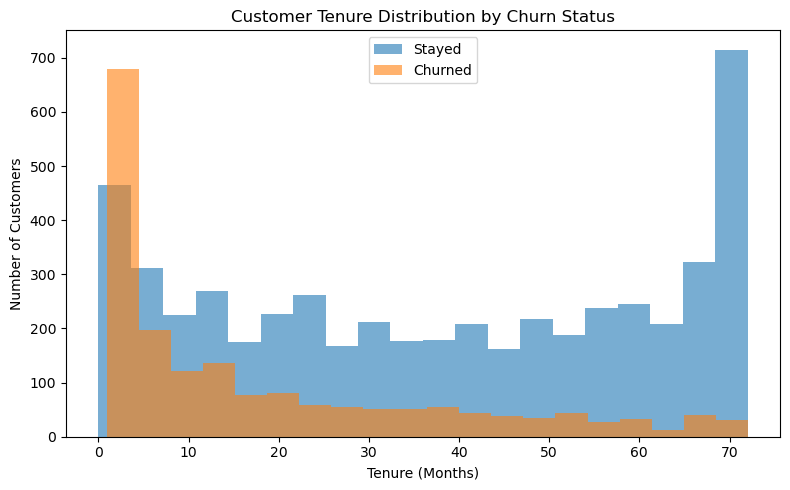

Median tenure of customers who stayed: 38.0 months
Median tenure of customers who churned: 10.0 months


In [31]:

import matplotlib.pyplot as plt

# Separate tenure by churn status
stayed = df.loc[df["Churn"] == "No", "tenure"]
churned = df.loc[df["Churn"] == "Yes", "tenure"]

# Compare tenure distributions
plt.figure(figsize=(8, 5))

plt.hist(
    stayed,
    bins=20,
    alpha=0.6,
    label="Stayed"
)

plt.hist(
    churned,
    bins=20,
    alpha=0.6,
    label="Churned"
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

# Compare median tenure
print("Median tenure of customers who stayed:",
      stayed.median(), "months")

print("Median tenure of customers who churned:",
      churned.median(), "months")


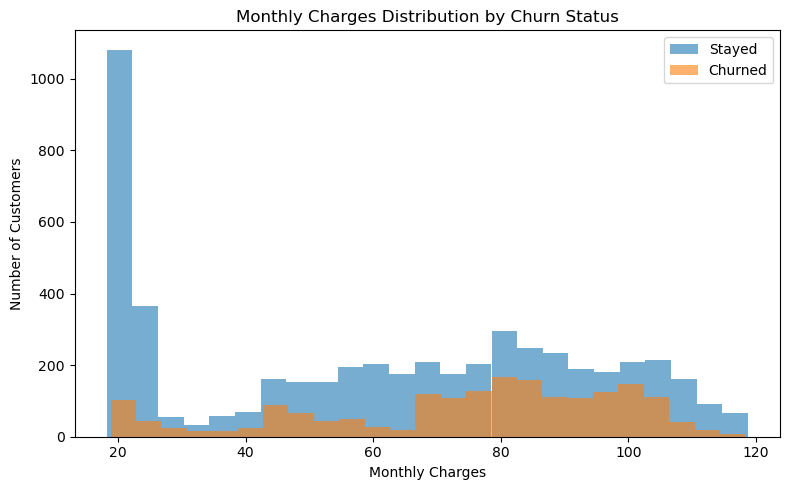

Median monthly charges of customers who stayed: 64.43
Median monthly charges of customers who churned: 79.65


In [32]:

import matplotlib.pyplot as plt

# Separate monthly charges by churn status
stayed_charges = df.loc[
    df["Churn"] == "No", "MonthlyCharges"
]

churned_charges = df.loc[
    df["Churn"] == "Yes", "MonthlyCharges"
]

# Compare distributions
plt.figure(figsize=(8, 5))

plt.hist(
    stayed_charges,
    bins=25,
    alpha=0.6,
    label="Stayed"
)

plt.hist(
    churned_charges,
    bins=25,
    alpha=0.6,
    label="Churned"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

# Compare median charges
print(
    "Median monthly charges of customers who stayed:",
    round(stayed_charges.median(), 2)
)

print(
    "Median monthly charges of customers who churned:",
    round(churned_charges.median(), 2)
)


Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Yes, dtype: float64


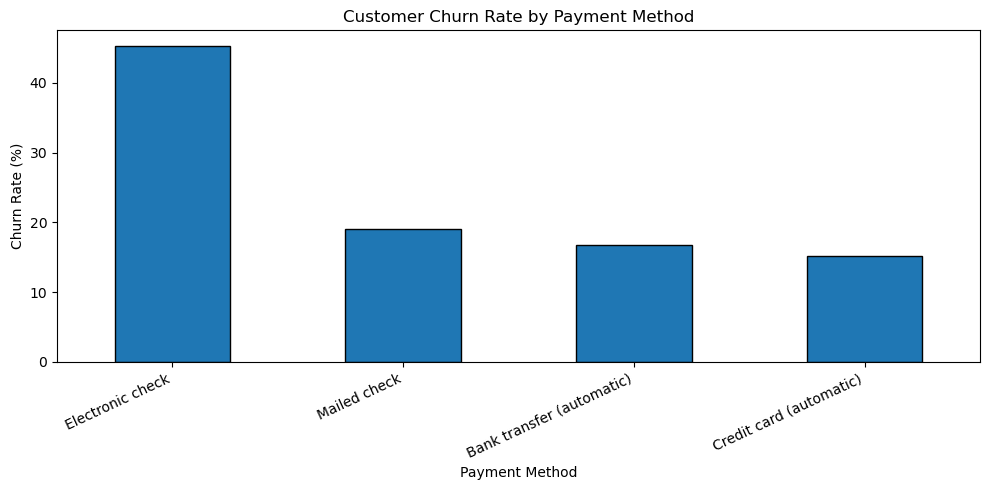

In [33]:

import matplotlib.pyplot as plt
import pandas as pd

# Calculate churn percentage within each payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

# Extract churn rates and sort
payment_churn_rate = payment_churn["Yes"].sort_values(
    ascending=False
)

print("Churn rate by payment method:")
print(payment_churn_rate.round(2))

# Visualize the results
plt.figure(figsize=(10, 5))

payment_churn_rate.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 8. Train/Test Split

In [34]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["customerID", "Churn"]).copy()
y = df["Churn"].copy()

# Convert TotalCharges to numeric.
# Blank or invalid entries become NaN and can be handled
# by the numerical imputer in your preprocessing pipeline.
X["TotalCharges"] = pd.to_numeric(
    X["TotalCharges"], errors="coerce"
)

# Step 1: Reserve 20% for final testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 2: Split the remaining 80% into training and validation
# 20% of 80% = 16% of the original dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.20,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nChurn percentage in each set:")
print("Train:", round((y_train == "Yes").mean() * 100, 2), "%")
print("Validation:", round((y_val == "Yes").mean() * 100, 2), "%")
print("Test:", round((y_test == "Yes").mean() * 100, 2), "%")

Training set: (4507, 19)
Validation set: (1127, 19)
Test set: (1409, 19)

Churn percentage in each set:
Train: 26.54 %
Validation: 26.53 %
Test: 26.54 %


In [35]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Preprocessing for numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using training data only
model.fit(X_train, y_train)

print("\nLogistic Regression model trained successfully!")

<ipython-input-35-68e062913314>:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Logistic Regression model trained successfully!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict churn labels
y_val_pred = model.predict(X_val)

# Predict probability of churn ("Yes")
y_val_proba = model.predict_proba(X_val)[:, 1]

# Calculate performance metrics
print("Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("Churn Precision:",
      round(precision_score(y_val, y_val_pred, pos_label="Yes"), 4))

print("Churn Recall:",
      round(recall_score(y_val, y_val_pred, pos_label="Yes"), 4))

print("Churn F1-Score:",
      round(f1_score(y_val, y_val_pred, pos_label="Yes"), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          (y_val == "Yes").astype(int),
          y_val_proba
      ), 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.8154
Churn Precision: 0.6936
Churn Recall: 0.5452
Churn F1-Score: 0.6105
ROC-AUC: 0.8482

Detailed Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.91      0.88       828
         Yes       0.69      0.55      0.61       299

    accuracy                           0.82      1127
   macro avg       0.77      0.73      0.74      1127
weighted avg       0.81      0.82      0.81      1127



In [37]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:
    # Convert probabilities into Yes/No predictions
    y_pred_threshold = [
        "Yes" if probability >= threshold else "No"
        for probability in y_val_proba
    ]

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_threshold, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, y_pred_threshold, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_val, y_pred_threshold, pos_label="Yes"
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-Score
      0.30     0.5433  0.7559    0.6322
      0.35     0.5808  0.7090    0.6386
      0.40     0.6173  0.6689    0.6421
      0.45     0.6593  0.6020    0.6294
      0.50     0.6936  0.5452    0.6105
      0.55     0.7317  0.5017    0.5952
      0.60     0.7267  0.3645    0.4855


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict churn probabilities for the test set
y_test_proba = model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
selected_threshold = 0.40

y_test_pred = [
    "Yes" if probability >= selected_threshold else "No"
    for probability in y_test_proba
]

print("Selected threshold:", selected_threshold)
print("Test Accuracy:", round(
    accuracy_score(y_test, y_test_pred), 4
))
print("Test Churn Precision:", round(
    precision_score(y_test, y_test_pred, pos_label="Yes"), 4
))
print("Test Churn Recall:", round(
    recall_score(y_test, y_test_pred, pos_label="Yes"), 4
))
print("Test F1-Score:", round(
    f1_score(y_test, y_test_pred, pos_label="Yes"), 4
))
print("Test ROC-AUC:", round(
    roc_auc_score((y_test == "Yes").astype(int), y_test_proba), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, y_test_pred, labels=["No", "Yes"]
))


Selected threshold: 0.4
Test Accuracy: 0.7821
Test Churn Precision: 0.577
Test Churn Recall: 0.6711
Test F1-Score: 0.6205
Test ROC-AUC: 0.8426

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.82      0.85      1035
         Yes       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.79      0.78      0.79      1409

Confusion Matrix:
[[851 184]
 [123 251]]


In [39]:
import pandas as pd

# Get the transformed feature names from preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get the trained Logistic Regression coefficients
coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort features by coefficient
feature_importance = feature_importance.sort_values(
    by="Coefficient", ascending=False
)

print("Top 15 features associated with higher churn scores:")
display(feature_importance.head(15).round(4))

print("Top 15 features associated with lower churn scores:")
display(feature_importance.tail(15).sort_values(
    by="Coefficient"
).round(4))

Top 15 features associated with higher churn scores:


,Feature,Coefficient
36,cat__Contract_Month-to-month,0.6478
16,cat__InternetService_Fiber optic,0.5978
3,num__TotalCharges,0.5055
32,cat__StreamingTV_Yes,0.1982
35,cat__StreamingMovies_Yes,0.1683
18,cat__OnlineSecurity_No,0.1571
27,cat__TechSupport_No,0.1444
43,cat__PaymentMethod_Electronic check,0.1417
14,cat__MultipleLines_Yes,0.1009
0,num__SeniorCitizen,0.0542


Top 15 features associated with lower churn scores:


,Feature,Coefficient
1,num__tenure,-1.2163
38,cat__Contract_Two year,-0.8709
15,cat__InternetService_DSL,-0.6257
2,num__MonthlyCharges,-0.4838
12,cat__MultipleLines_No,-0.3021
39,cat__PaperlessBilling_No,-0.2973
9,cat__Dependents_Yes,-0.2764
17,cat__InternetService_No,-0.2753
34,cat__StreamingMovies_No internet service,-0.2753
31,cat__StreamingTV_No internet service,-0.2753


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train on training data only
rf_model.fit(X_train, y_train)

# Evaluate using validation data
rf_val_pred = rf_model.predict(X_val)
rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest — Validation Results")
print("Accuracy:", round(
    accuracy_score(y_val, rf_val_pred), 4
))
print("Churn Precision:", round(
    precision_score(y_val, rf_val_pred, pos_label="Yes"), 4
))
print("Churn Recall:", round(
    recall_score(y_val, rf_val_pred, pos_label="Yes"), 4
))
print("F1-Score:", round(
    f1_score(y_val, rf_val_pred, pos_label="Yes"), 4
))
print("ROC-AUC:", round(
    roc_auc_score(
        (y_val == "Yes").astype(int),
        rf_val_proba
    ), 4
))

Random Forest — Validation Results
Accuracy: 0.7941
Churn Precision: 0.6044
Churn Recall: 0.6488
F1-Score: 0.6258
ROC-AUC: 0.8386


In [41]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

rf_threshold_results = []

for threshold in thresholds:
    rf_pred_threshold = [
        "Yes" if probability >= threshold else "No"
        for probability in rf_val_proba
    ]

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, rf_pred_threshold, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, rf_pred_threshold, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_val, rf_pred_threshold, pos_label="Yes"
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print(rf_threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-Score
      0.30     0.4832  0.8161    0.6070
      0.35     0.5121  0.7793    0.6180
      0.40     0.5314  0.7358    0.6171
      0.45     0.5718  0.6923    0.6263
      0.50     0.6044  0.6488    0.6258
      0.55     0.6477  0.5719    0.6075
      0.60     0.6726  0.5017    0.5747


In [42]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Threshold": 0.40,
        "Precision": 0.6173,
        "Recall": 0.6689,
        "F1-Score": 0.6421,
        "ROC-AUC": 0.8482
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.45,
        "Precision": 0.5718,
        "Recall": 0.6923,
        "F1-Score": 0.6263,
        "ROC-AUC": 0.8386
    }
])

print(comparison.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression       0.40     0.6173  0.6689    0.6421   0.8482
      Random Forest       0.45     0.5718  0.6923    0.6263   0.8386


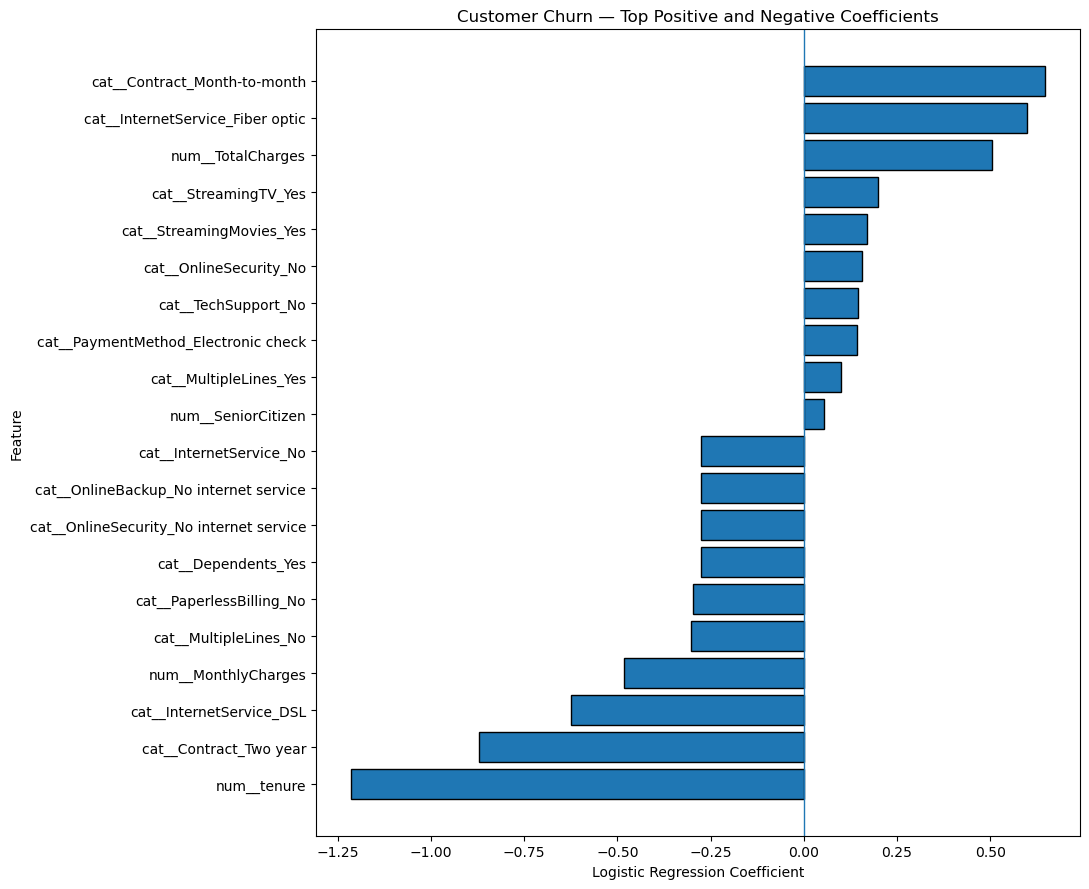

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Extract feature names and coefficients from trained model
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Select the strongest positive and negative coefficients
top_positive = feature_importance.nlargest(
    10, "Coefficient"
)

top_negative = feature_importance.nsmallest(
    10, "Coefficient"
)

plot_data = pd.concat([
    top_negative,
    top_positive
]).sort_values("Coefficient")

# Create the visualization
plt.figure(figsize=(11, 9))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    edgecolor="black"
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Customer Churn — Top Positive and Negative Coefficients")
plt.tight_layout()
plt.show()


## 20. Predict Churn for a New Customer

In this step, I’ll test the trained model using a hypothetical customer’s details to predict whether they are likely to churn.

The model will return the **predicted churn outcome** and the **probability of churn**, helping demonstrate how the model can be applied to a new customer.

In [44]:
## 20. Predict Churn for a New Customer

import pandas as pd

# Create a hypothetical new customer
new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["No"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["No"],
    "StreamingMovies": ["No"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [80.0],
    "TotalCharges": [400.0]
})

# Predict probability of churn using our trained model
churn_probability = model.predict_proba(new_customer)[0, 1]

# Use the threshold selected during validation
selected_threshold = 0.40

# Convert probability into a prediction
prediction = (
    "Yes" if churn_probability >= selected_threshold else "No"
)

# Display results
print("Customer Churn Prediction")
print("-------------------------")
print("Predicted outcome:",
      "Churn" if prediction == "Yes" else "Stay")
print(f"Probability of churn: {churn_probability:.2%}")
print(f"Probability of staying: {1 - churn_probability:.2%}")
print(f"Decision threshold: {selected_threshold:.2f}")

Customer Churn Prediction
-------------------------
Predicted outcome: Churn
Probability of churn: 62.52%
Probability of staying: 37.48%
Decision threshold: 0.40


## 21. Probability-based prediction

In [45]:
# Predict probabilities for the new customer
probabilities = model.predict_proba(new_customer)[0]

# Identify the correct class positions
classes = model.named_steps["classifier"].classes_

stay_index = list(classes).index("No")
churn_index = list(classes).index("Yes")

print(f"Probability of staying: {probabilities[stay_index]:.2%}")
print(f"Probability of churning: {probabilities[churn_index]:.2%}")

Probability of staying: 37.48%
Probability of churning: 62.52%


## 22. Business decision threshold

The model produces a probability. A business does not have to use the default 0.50 threshold.

For example, if the company wants to proactively contact more at-risk customers, it could use a lower threshold.


In [46]:
threshold = 0.40

churn_probability = probabilities[churn_index]

custom_prediction = (
    "Yes" if churn_probability >= threshold else "No"
)

print("Decision threshold:", threshold)
print("Predicted outcome:",
      "Churn" if custom_prediction == "Yes" else "Stay")
print(f"Churn probability: {churn_probability:.2%}")

Decision threshold: 0.4
Predicted outcome: Churn
Churn probability: 62.52%


## 23. Quick model recap

In [47]:
print("ML WORKFLOW")
print("1. Define the business problem")
print("2. Select meaningful features")
print("3. Separate features and target")
print("4. Split into training and testing data")
print("5. Preprocess numerical and categorical data")
print("6. Train Logistic Regression")
print("7. Evaluate with suitable metrics")
print("8. Predict for new customers")
print("9. Convert probabilities into business decisions")


ML WORKFLOW
1. Define the business problem
2. Select meaningful features
3. Separate features and target
4. Split into training and testing data
5. Preprocess numerical and categorical data
6. Train Logistic Regression
7. Evaluate with suitable metrics
8. Predict for new customers
9. Convert probabilities into business decisions
